# **Best Regression Model Selection**
Dataset: Concrete (target `strength`, MPa)

All models in one notebook, each tuned with cross-validation, then compared. The best one is selected by **CV R2** (the test set is never used for selection) and saved as `.pkl`.

| Type | Models |
|---|---|
| Linear | Linear, Polynomial, Ridge, Lasso, ElasticNet |
| Poly + Regularization | Poly+Ridge, Poly+Lasso, Poly+ElasticNet |
| Distance / Kernel | KNN, SVR |
| Tree | Decision Tree |
| Bagging | Bagging |
| Boosting | AdaBoost, Gradient Boosting, HistGradientBoosting, XGBoost, LightGBM |
| Ensemble | Voting, Stacking (built from the best tuned models above) |

Imbalance handling: very high strength samples are rare, so the split and the CV are **stratified** on strength ranges.

### 1. Import

In [22]:
# In Google Colab xgboost and lightgbm are already installed. Locally run:  pip install xgboost lightgbm
import itertools, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, GridSearchCV,
                                     RandomizedSearchCV, cross_val_predict, cross_val_score)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (BaggingRegressor, AdaBoostRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, VotingRegressor, StackingRegressor)
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### 2. Dataset and Stratified Split

In [23]:
df=pd.read_csv('../1. Data_Preprocessing/For_Regression/concrete_after_preprocessing.csv')
x = df.drop('strength', axis=1)
y = df['strength']

#Strength ranges (used only for stratification)
bins = pd.cut(y, bins=[0, 20, 35, 50, 65, 100], labels=False)

x_train, x_test, y_train, y_test, bins_train, _ = train_test_split(
    x, y, bins, test_size=0.2, random_state=42, stratify=bins)
print(x_train.shape, x_test.shape)

#Stratified 5-fold CV (same folds for every model = fair comparison)
cv = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(x_train, bins_train))

(804, 8) (201, 8)


### 3. Models and parameter search space
Each entry: `name: (model, parameters, type, n_iter)`
- `n_iter = None` -> **GridSearchCV** (small grid, every combination is tried)
- `n_iter = 25` -> **RandomizedSearchCV** (big grid, 25 random combinations are tried)

Scale-sensitive models (linear, KNN, SVR) have a `StandardScaler` inside their Pipeline. Tree models do not need scaling.

In [24]:
a_ridge = np.logspace(-3, 3, 13)      # alpha values for Ridge
a_l1    = np.logspace(-4, 1, 11)      # alpha values for Lasso / ElasticNet
lr      = [0.01, 0.03, 0.05, 0.1, 0.2]

def scaled(model):                     # StandardScaler + model
    return Pipeline([('scaler', StandardScaler()), ('model', model)])

def poly_scaled(model):                # PolynomialFeatures + StandardScaler + model
    return Pipeline([('poly', PolynomialFeatures(include_bias=False)),
                     ('scaler', StandardScaler()), ('model', model)])

models = {
    # ---------------- Linear ----------------
    'Linear':       (scaled(LinearRegression()), {}, 'Linear', None),
    'Polynomial':   (poly_scaled(LinearRegression()), {'poly__degree': [1, 2, 3, 4]}, 'Linear', None),
    'Ridge':        (scaled(Ridge()), {'model__alpha': a_ridge}, 'Linear', None),
    'Lasso':        (scaled(Lasso(max_iter=50000)), {'model__alpha': a_l1}, 'Linear', None),
    'ElasticNet':   (scaled(ElasticNet(max_iter=50000)),
                     {'model__alpha': a_l1, 'model__l1_ratio': [0.1, 0.3, 0.5, 0.7, 0.9]}, 'Linear', None),

    # ---------------- Poly + Regularization ----------------
    'Poly+Ridge':   (poly_scaled(Ridge()),
                     {'poly__degree': [2, 3], 'model__alpha': np.logspace(-2, 3, 11)}, 'Poly+Reg', None),
    'Poly+Lasso':   (poly_scaled(Lasso(max_iter=50000)),
                     {'poly__degree': [2, 3], 'model__alpha': np.logspace(-3, 0, 7)}, 'Poly+Reg', None),
    'Poly+ElasticNet': (poly_scaled(ElasticNet(max_iter=50000)),
                     {'poly__degree': [2, 3], 'model__alpha': np.logspace(-3, 0, 7),
                      'model__l1_ratio': [0.2, 0.5, 0.8]}, 'Poly+Reg', None),

    # ---------------- Distance / Kernel ----------------
    'KNN':          (scaled(KNeighborsRegressor()),
                     {'model__n_neighbors': list(range(1, 31)), 'model__weights': ['uniform', 'distance'],
                      'model__p': [1, 2]}, 'Distance/Kernel', None),
    'SVR':          (scaled(SVR()),
                     [{'model__kernel': ['rbf'], 'model__C': [1, 10, 100, 1000],
                       'model__gamma': ['scale', 0.01, 0.05, 0.1, 0.5], 'model__epsilon': [0.1, 1, 3]},
                      {'model__kernel': ['linear'], 'model__C': [0.1, 1, 10, 100],
                       'model__epsilon': [0.1, 1, 3]}], 'Distance/Kernel', None),

    # ---------------- Tree ----------------
    'DecisionTree': (DecisionTreeRegressor(random_state=42),
                     {'max_depth': [3, 5, 7, 9, 12, None], 'min_samples_split': [2, 5, 10, 20],
                      'min_samples_leaf': [1, 2, 5, 10], 'ccp_alpha': [0, 0.01, 0.1, 0.5]}, 'Tree', None),

    # ---------------- Bagging ----------------
    'Bagging':      (BaggingRegressor(estimator=DecisionTreeRegressor(random_state=42), random_state=42),
                     {'n_estimators': [50, 100, 200], 'max_samples': [0.6, 0.8, 1.0],
                      'max_features': [0.6, 0.8, 1.0], 'estimator__max_depth': [None, 10]}, 'Bagging', 12),

    # ---------------- Boosting ----------------
    'AdaBoost':     (AdaBoostRegressor(estimator=DecisionTreeRegressor(), random_state=42),
                     {'n_estimators': [50, 100, 200, 300], 'learning_rate': [0.01, 0.05, 0.1, 0.5, 1.0],
                      'loss': ['linear', 'square'], 'estimator__max_depth': [3, 5, 7, 9]}, 'Boosting', 25),
    'GradientBoosting': (GradientBoostingRegressor(random_state=42),
                     {'n_estimators': [100, 200, 300, 500], 'learning_rate': lr, 'max_depth': [2, 3, 4, 5],
                      'subsample': [0.7, 0.85, 1.0], 'min_samples_leaf': [1, 3, 5]}, 'Boosting', 25),
    'HistGradientBoosting': (HistGradientBoostingRegressor(random_state=42),
                     {'max_iter': [100, 200, 300, 500], 'learning_rate': lr, 'max_depth': [None, 3, 5, 7],
                      'max_leaf_nodes': [15, 31, 63], 'min_samples_leaf': [5, 10, 20],
                      'l2_regularization': [0, 0.1, 1]}, 'Boosting', 25),
    'XGBoost':      (XGBRegressor(random_state=42, n_jobs=1, verbosity=0),
                     {'n_estimators': [100, 200, 300, 500], 'learning_rate': lr, 'max_depth': [3, 4, 5, 6, 8],
                      'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0],
                      'min_child_weight': [1, 3, 5], 'reg_lambda': [0.1, 1, 5]}, 'Boosting', 25),
    'LightGBM':     (LGBMRegressor(random_state=42, n_jobs=1, verbose=-1, subsample_freq=1),
                     {'n_estimators': [100, 200, 300, 500], 'learning_rate': lr, 'num_leaves': [15, 31, 63],
                      'max_depth': [-1, 5, 8], 'subsample': [0.7, 0.85, 1.0], 'colsample_bytree': [0.6, 0.8, 1.0],
                      'min_child_samples': [5, 10, 20], 'reg_lambda': [0, 1, 5]}, 'Boosting', 25),
}
print(len(models), 'models to tune')

17 models to tune


### 4. Tune every model (best parameters)

In [25]:
def evaluate(name, mtype, model, cv_r2, train_r2, params):
    # test-set scores of a fitted model
    pred = model.predict(x_test)
    return {'Model': name, 'Type': mtype, 'Train_R2': train_r2, 'CV_R2': cv_r2,
            'Test_R2': r2_score(y_test, pred), 'Test_MAE': mean_absolute_error(y_test, pred),
            'Test_RMSE': np.sqrt(mean_squared_error(y_test, pred)), 'Best_Params': params}

results, best_estimators = [], {}

In [ ]:
%%time
for name, (model, params, mtype, n_iter) in models.items():
    t0 = time.time()
    if n_iter:   # big space -> random search
        search = RandomizedSearchCV(model, params, n_iter=n_iter, cv=cv, scoring='r2', n_jobs=-1,
                                    random_state=42, return_train_score=True)
    else:        # small space -> grid search
        search = GridSearchCV(model, params, cv=cv, scoring='r2', n_jobs=-1, return_train_score=True)
    search.fit(x_train, y_train)

    train_r2 = search.cv_results_['mean_train_score'][search.best_index_]
    row = evaluate(name, mtype, search.best_estimator_, search.best_score_, train_r2, search.best_params_)
    results.append(row)
    best_estimators[name] = search.best_estimator_
    print(f"{name:<21} CV R2 = {row['CV_R2']:.4f} | Test R2 = {row['Test_R2']:.4f} | {time.time()-t0:.0f}s")

Linear                CV R2 = 0.8106 | Test R2 = 0.7878 | 23s
Polynomial            CV R2 = 0.8982 | Test R2 = 0.8340 | 14s
Ridge                 CV R2 = 0.8106 | Test R2 = 0.7876 | 1s
Lasso                 CV R2 = 0.8106 | Test R2 = 0.7877 | 1s
ElasticNet            CV R2 = 0.8106 | Test R2 = 0.7874 | 2s
Poly+Ridge            CV R2 = 0.9082 | Test R2 = 0.8793 | 4s
Poly+Lasso            CV R2 = 0.9088 | Test R2 = 0.8777 | 9s
Poly+ElasticNet       CV R2 = 0.9085 | Test R2 = 0.8828 | 12s
KNN                   CV R2 = 0.8704 | Test R2 = 0.8990 | 10s
SVR                   CV R2 = 0.9138 | Test R2 = 0.8982 | 24s
DecisionTree          CV R2 = 0.8346 | Test R2 = 0.7308 | 20s
Bagging               CV R2 = 0.8996 | Test R2 = 0.8696 | 18s
AdaBoost              CV R2 = 0.8970 | Test R2 = 0.8857 | 37s
GradientBoosting      CV R2 = 0.9316 | Test R2 = 0.9119 | 30s


### 5. Ensembles: Voting and Stacking
They are built from the **top 8 tuned models** (by CV R2).
- **Voting:** average of a team of models. We test every team (2 or more of the 8 models) and pick the best by CV.
- **Stacking:** a meta model (Lasso with positive weights) learns how much to trust each of the 8 models.

In [ ]:
%%time
single_df = pd.DataFrame(results).sort_values('CV_R2', ascending=False).reset_index(drop=True)
top_names = list(single_df['Model'][:8])
print('Top 8 models used for the ensembles:', top_names)

# ---- Voting: out-of-fold predictions of each model, then test every team ----
oof = {n: cross_val_predict(clone(best_estimators[n]), x_train, y_train, cv=cv, n_jobs=-1) for n in top_names}

best_team, best_team_r2 = None, -1
for size in range(2, len(top_names) + 1):
    for team in itertools.combinations(top_names, size):
        r2_team = r2_score(y_train, np.mean([oof[n] for n in team], axis=0))
        if r2_team > best_team_r2:
            best_team, best_team_r2 = list(team), r2_team
print('Best voting team:', best_team)

voting = VotingRegressor([(n, clone(best_estimators[n])) for n in best_team])
voting_cv = cross_val_score(voting, x_train, y_train, cv=cv, scoring='r2').mean()
voting.fit(x_train, y_train)
results.append(evaluate('Voting', 'Ensemble', voting, voting_cv, np.nan, {'team': best_team}))
best_estimators['Voting'] = voting
print(f"Voting   CV R2 = {voting_cv:.4f} | Test R2 = {results[-1]['Test_R2']:.4f}")

# ---- Stacking: meta model learns the weight of each model ----
stacking = StackingRegressor(
    estimators=[(n, clone(best_estimators[n])) for n in top_names],
    final_estimator=Lasso(alpha=0.01, positive=True),
    cv=KFold(n_splits=5, shuffle=True, random_state=42), n_jobs=-1)
stacking_cv = cross_val_score(stacking, x_train, y_train, cv=cv, scoring='r2').mean()
stacking.fit(x_train, y_train)
results.append(evaluate('Stacking', 'Ensemble', stacking, stacking_cv, np.nan, {'base_models': top_names}))
best_estimators['Stacking'] = stacking
print(f"Stacking CV R2 = {stacking_cv:.4f} | Test R2 = {results[-1]['Test_R2']:.4f}")

Top 8 models used for the ensembles: ['LightGBM', 'HistGradientBoosting', 'XGBoost', 'GradientBoosting', 'SVR', 'Poly+Lasso', 'Poly+ElasticNet', 'Poly+Ridge']
Best voting team: ['LightGBM', 'HistGradientBoosting', 'GradientBoosting', 'Poly+Lasso']
Voting   CV R2 = 0.9415 | Test R2 = 0.9208
Stacking CV R2 = 0.9381 | Test R2 = 0.9231
CPU times: total: 32.4 s
Wall time: 1min 4s


### 6. All models compared (sorted by CV R2)

In [ ]:
results_df = pd.DataFrame(results).sort_values('CV_R2', ascending=False).reset_index(drop=True)
results_df.index = results_df.index + 1          # rank starts at 1
results_df.index.name = 'Rank'
results_df.drop(columns='Best_Params').round(4)

,Model,Type,Train_R2,CV_R2,Test_R2,Test_MAE,Test_RMSE
Rank,,,,,,,
1,Voting,Ensemble,NaN,0.9415,0.9208,2.8320,4.6066
2,Stacking,Ensemble,NaN,0.9381,0.9231,2.7903,4.5394
3,LightGBM,Boosting,0.9951,0.9334,0.9102,2.8889,4.9054
4,HistGradientBoosting,Boosting,0.9908,0.9332,0.9158,2.9709,4.7491
5,XGBoost,Boosting,0.9827,0.9322,0.9188,2.9353,4.6634
6,GradientBoosting,Boosting,0.9883,0.9316,0.9119,2.9677,4.8575
7,SVR,Distance/Kernel,0.9534,0.9138,0.8982,3.6819,5.2206
8,Poly+Lasso,Poly+Reg,0.9390,0.9088,0.8777,4.2756,5.7238
9,Poly+ElasticNet,Poly+Reg,0.9502,0.9085,0.8828,4.0784,5.6034


### 7. Best model and its parameters

In [ ]:
best = results_df.iloc[0]
best_name = best['Model']

print('===== BEST REGRESSION MODEL =====')
print('Model     :', best_name, f"({best['Type']})")
print(f"CV R2     : {best['CV_R2']:.4f}")
print(f"Test R2   : {best['Test_R2']:.4f}")
print(f"Test MAE  : {best['Test_MAE']:.3f} MPa")
print(f"Test RMSE : {best['Test_RMSE']:.3f} MPa")
print('\nBest Parameters:')
if isinstance(best['Best_Params'], dict):
    for k, v in best['Best_Params'].items():
        print(f'   {k:<22}: {v}')

print('\n===== BEST MODEL OF EACH TYPE =====')
results_df.sort_values('CV_R2', ascending=False).groupby('Type').head(1)[['Type', 'Model', 'CV_R2', 'Test_R2', 'Test_MAE']].round(4)

===== BEST REGRESSION MODEL =====
Model     : Voting (Ensemble)
CV R2     : 0.9415
Test R2   : 0.9208
Test MAE  : 2.832 MPa
Test RMSE : 4.607 MPa

Best Parameters:
   team                  : ['LightGBM', 'HistGradientBoosting', 'GradientBoosting', 'Poly+Lasso']

===== BEST MODEL OF EACH TYPE =====


,Type,Model,CV_R2,Test_R2,Test_MAE
Rank,,,,,
1,Ensemble,Voting,0.9415,0.9208,2.8320
3,Boosting,LightGBM,0.9334,0.9102,2.8889
7,Distance/Kernel,SVR,0.9138,0.8982,3.6819
8,Poly+Reg,Poly+Lasso,0.9088,0.8777,4.2756
11,Bagging,Bagging,0.8996,0.8696,3.9022
12,Linear,Polynomial,0.8982,0.8340,4.0257
15,Tree,DecisionTree,0.8346,0.7308,5.0560


### 8. Parameters of every model

In [ ]:
for _, r in results_df.iterrows():
    print(f"{r['Model']:<21}", r['Best_Params'])

Voting                {'team': ['LightGBM', 'HistGradientBoosting', 'GradientBoosting', 'Poly+Lasso']}
Stacking              {'base_models': ['LightGBM', 'HistGradientBoosting', 'XGBoost', 'GradientBoosting', 'SVR', 'Poly+Lasso', 'Poly+ElasticNet', 'Poly+Ridge']}
LightGBM              {'subsample': 0.7, 'reg_lambda': 5, 'num_leaves': 15, 'n_estimators': 500, 'min_child_samples': 10, 'max_depth': -1, 'learning_rate': 0.2, 'colsample_bytree': 1.0}
HistGradientBoosting  {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 300, 'max_depth': 5, 'learning_rate': 0.2, 'l2_regularization': 0}
XGBoost               {'subsample': 0.85, 'reg_lambda': 5, 'n_estimators': 500, 'min_child_weight': 5, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 0.8}
GradientBoosting      {'subsample': 0.85, 'n_estimators': 500, 'min_samples_leaf': 1, 'max_depth': 3, 'learning_rate': 0.1}
SVR                   {'model__C': 100, 'model__epsilon': 3, 'model__gamma': 0.1, 'model__kernel': 'rbf'}
Poly+L

### 9. Visualization

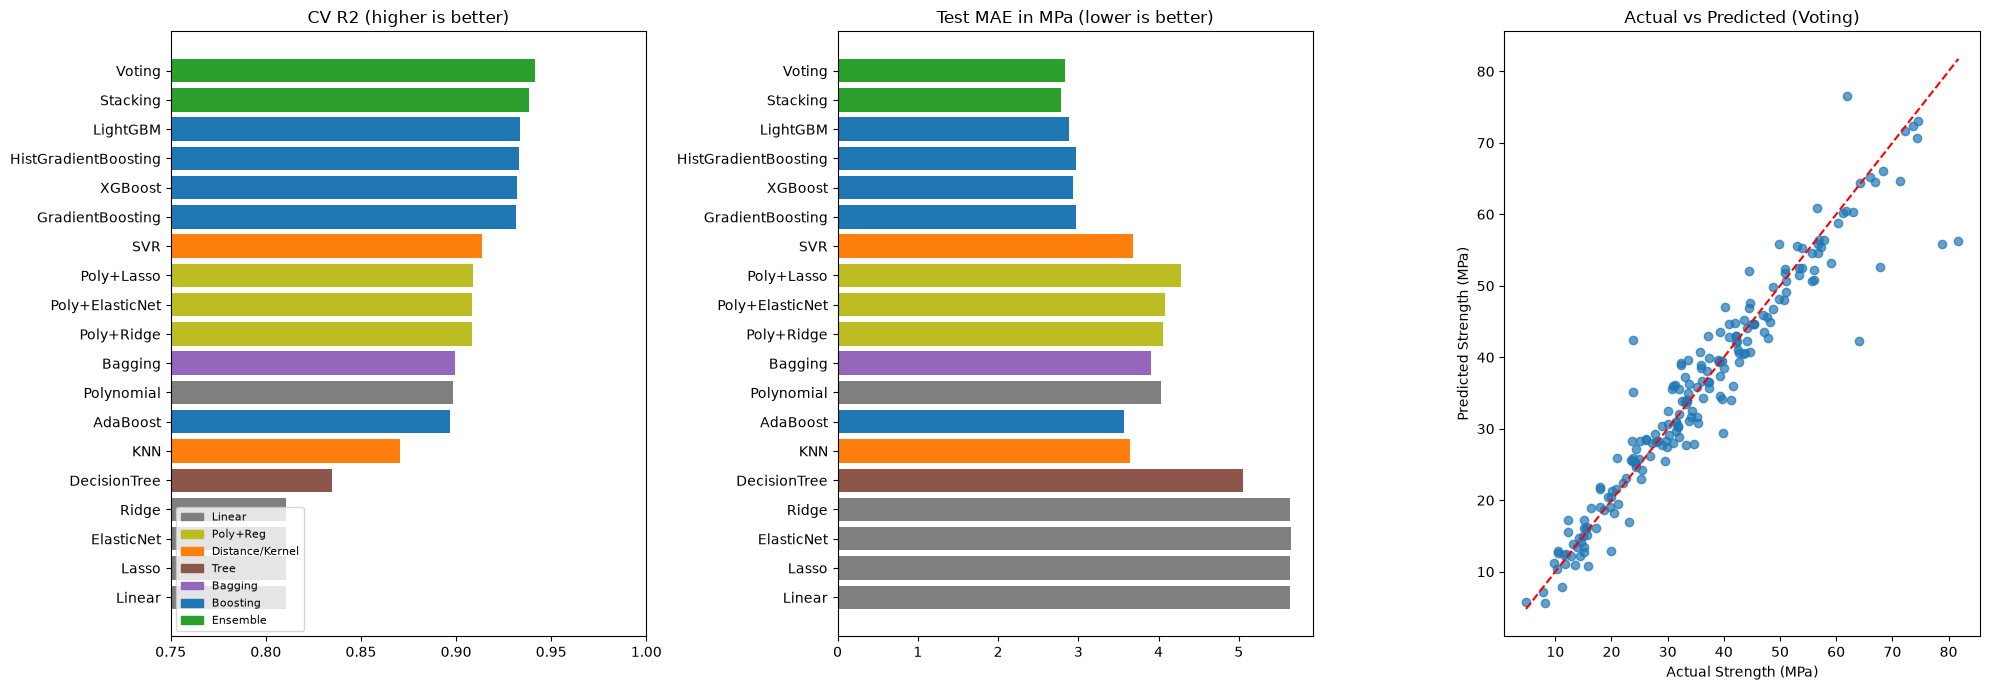

In [ ]:
type_colors = {'Linear': 'tab:gray', 'Poly+Reg': 'tab:olive', 'Distance/Kernel': 'tab:orange', 'Tree': 'tab:brown',
              'Bagging': 'tab:purple', 'Boosting': 'tab:blue', 'Ensemble': 'tab:green'}
colors = results_df['Type'].map(type_colors)

fig, ax = plt.subplots(1, 3, figsize=(20, 7))

#CV R2
ax[0].barh(results_df['Model'], results_df['CV_R2'], color=colors)
ax[0].invert_yaxis(); ax[0].set_xlim(0.75, 1); ax[0].set_title('CV R2 (higher is better)')

#Test MAE
ax[1].barh(results_df['Model'], results_df['Test_MAE'], color=colors)
ax[1].invert_yaxis(); ax[1].set_title('Test MAE in MPa (lower is better)')

#Actual vs Predicted (best model)
y_pred_best = best_estimators[best_name].predict(x_test)
ax[2].scatter(y_test, y_pred_best, alpha=0.7)
ax[2].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
ax[2].set_xlabel('Actual Strength (MPa)'); ax[2].set_ylabel('Predicted Strength (MPa)')
ax[2].set_title(f'Actual vs Predicted ({best_name})')

handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in type_colors.values()]
ax[0].legend(handles, type_colors.keys(), loc='lower left', fontsize=8)
plt.tight_layout(); plt.show()

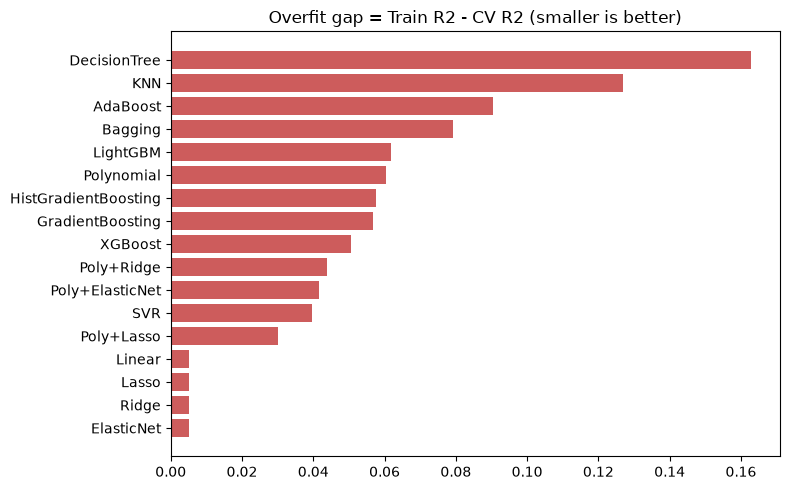

In [ ]:
#Overfitting check: Train R2 vs CV R2 (single models only)
g = results_df.dropna(subset=['Train_R2']).copy()
g['Gap'] = g['Train_R2'] - g['CV_R2']
g = g.sort_values('Gap')
plt.figure(figsize=(8, 5))
plt.barh(g['Model'], g['Gap'], color='indianred')
plt.title('Overfit gap = Train R2 - CV R2 (smaller is better)')
plt.tight_layout(); plt.show()

### 10. Save the best model (.pkl)
The best model (with its best parameters) is trained once more on all data, then saved with `joblib`.

In [ ]:
final_model = clone(best_estimators[best_name])
final_model.fit(x, y)

joblib.dump(final_model, 'best_regression_model.pkl', compress=3)
results_df.to_csv('all_models_results.csv')
print('Saved: best_regression_model.pkl, all_models_results.csv')

Saved: best_regression_model.pkl, all_models_results.csv


### 11. Load and Predict
These 5 rows were also used to train the final model, so predictions look better than reality. This cell only checks that the saved file loads and works. The honest accuracy is the **Test R2** above (trained without the test rows).

In [ ]:
model = joblib.load('best_regression_model.pkl')

new_rows = x_test.iloc[:5]
print('Predicted strength:', model.predict(new_rows).round(2))
print('Actual strength   :', y_test.iloc[:5].round(2).values)

Predicted strength: [22.27 13.91 17.25 29.67 66.85]
Actual strength   : [21.97 15.07 18.03 30.23 68.3 ]


### 12. Download (Google Colab only)

In [ ]:
try:
    from google.colab import files
    files.download('best_regression_model.pkl')
    files.download('all_models_results.csv')
except ImportError:
    print('Not Colab - files are saved in the notebook folder.')

Not Colab - files are saved in the notebook folder.
